#BIL485 Ödev-1: MNIST Veri Setiyle MLP Tabanlı El Yazısı Rakam Tanıma

**Hazırlayan: Elif Naz Üçkardeş-25120205047**

##**Amaç:**
Bu projeyi hazırlama amacımız MNIST veri setini kullanarak sıfırdan bir MLP modeli geliştirip modelin kendi hazırladığımız gerçek hayat el yazıları üzerindeki başarısını test etmek.

**Proje kapsamında CNN kullanılmamıştır.**


In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt
import numpy as np
import time
import cv2

##**Preprocessing(Ön İşleme):**

In [2]:
(train_images, train_labels), (test_images,test_labels) = mnist.load_data();

#reshaping:
train_images= train_images.reshape((60000, 28*28));
test_images=test_images.reshape((10000, 28*28));

#normalization:
train_images=train_images.astype("float32")/255;
test_images=test_images.astype("float32")/255;

#for validation:
val_images=train_images[:10000]
val_labels=train_labels[:10000]

#for training:
part_train_images= train_images[10000:]
part_train_labels=train_labels[10000:]

#for control:
print("egitim veri boyutu: ", part_train_images.shape);
print("validation veri boyutu: ", val_images.shape);
print("test veri boyutu: ",test_images.shape);

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
egitim veri boyutu:  (50000, 784)
validation veri boyutu:  (10000, 784)
test veri boyutu:  (10000, 784)


##**MLP Mimari:**

In [4]:
#mimari:
model=models.Sequential([
    layers.Dense(128, activation='relu', input_shape=(28*28,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
]);

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
              metrics=['accuracy']);
model.summary();

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

##**Eğitim:**

In [7]:
start_time=time.time();

gecmis=model.fit(part_train_images, part_train_labels, epochs=15, batch_size=128,
                      validation_data=(val_images, val_labels));

end_time=time.time();

#süre hesap:
egitim_sure=end_time - start_time;

print("Egitim Bitti");
print(f"Egitim Suresi: {egitim_sure:.2f} saniye");

Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9967 - loss: 0.0104 - val_accuracy: 0.9766 - val_loss: 0.1010
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9971 - loss: 0.0096 - val_accuracy: 0.9763 - val_loss: 0.1008
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9971 - loss: 0.0098 - val_accuracy: 0.9758 - val_loss: 0.1143
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9983 - loss: 0.0060 - val_accuracy: 0.9768 - val_loss: 0.1120
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9967 - loss: 0.0101 - val_accuracy: 0.9744 - val_loss: 0.1249
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9968 - loss: 0.0101 - val_accuracy: 0.9781 - val_loss: 0.0989
Epoch 7/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9984 - loss: 0.0050 - val_accuracy: 0.9806 - val_loss: 0.0983
Epoch 8/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9992 - loss: 0.0027 - val_accuracy: 0.

#**Grafikler:**

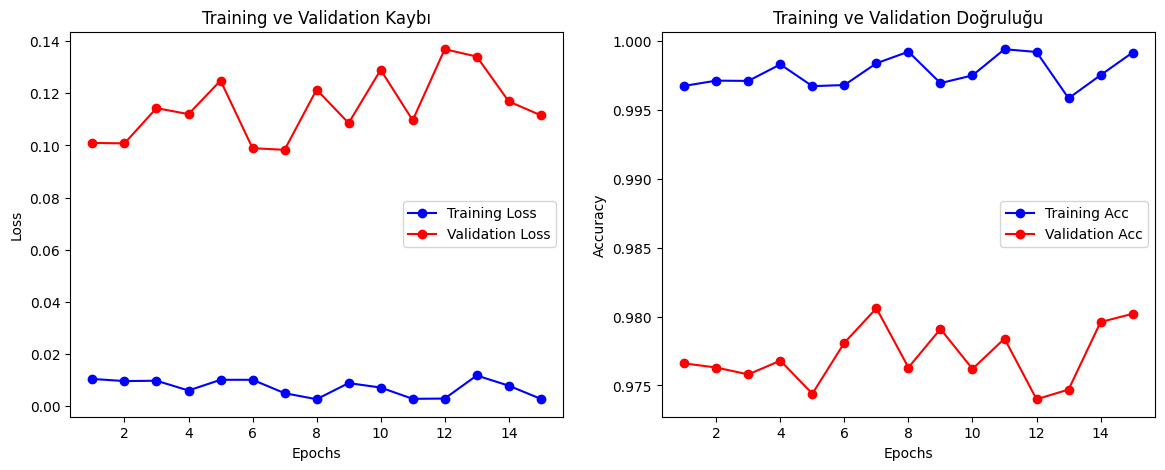

Test Verisi Değerlendirme
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9790 - loss: 0.1138
Test Accuracy: % 97.90
Test Loss: 0.1138


In [8]:
acc=gecmis.history['accuracy']
val_acc=gecmis.history['val_accuracy']
loss=gecmis.history['loss']
val_loss=gecmis.history['val_loss']

epochs= range(1, len(acc)+1)

plt.figure(figsize=(14,5));

#Loss Grafiği:
plt.subplot(1,2,1);

plt.plot(epochs, loss, 'bo-', label='Training Loss');
plt.plot(epochs, val_loss, 'ro-', label='Validation Loss');
plt.title('Training ve Validation Kaybı');
plt.xlabel('Epochs');
plt.ylabel('Loss');
plt.legend();

#Accuracy Grafiği:
plt.subplot(1,2,2);

plt.plot(epochs, acc, 'bo-', label='Training Acc');
plt.plot(epochs, val_acc, 'ro-', label='Validation Acc');
plt.title('Training ve Validation Doğruluğu');
plt.xlabel('Epochs');
plt.ylabel('Accuracy');
plt.legend();

plt.show();

#Test:

print("Test Verisi Değerlendirme");
test_loss, test_acc = model.evaluate(test_images, test_labels);
print(f"Test Accuracy: % {test_acc *100:.2f}");
print(f"Test Loss: {test_loss:.4f}");